# Basic grids: Q-learning vs greedy vs random

Three agents collect items on a 10×10 grid. Every collected item is worth 5 points and is replaced somewhere else at random.

- **Random** moves in a random direction.
- **Greedy** walks to the nearest item.
- **Q-learning** starts knowing nothing and learns which way to move from the points it gets. Its only view of the world is which direction the nearest item is in.

This notebook plays the experiment in `configs/q_vs_greedy.toml` (20 runs of 100 episodes, 100 steps each), records every move, and plots how the agents do over time.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Cyrl-Alt-Del/basic-grids/blob/main/basic_grids.ipynb)

In [1]:
# On Colab: fetch the code and install Polars. On your own computer this cell does nothing.
import os, sys

if "google.colab" in sys.modules and not os.path.exists("world.py"):
    !git clone -q https://github.com/Cyrl-Alt-Del/basic-grids.git
    %cd basic-grids
    %pip install -q "polars>=2.1"

In [2]:
%matplotlib inline
import json
import polars as pl
import analyse, data, run

config = run.load_config("configs/q_vs_greedy.toml")
experiment, ids = config["experiment"], run.run_ids(config)
config

{'experiment': 'q_vs_greedy',
 'seeds': [0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19],
 'episodes': 100,
 'world': {'width': 10,
  'height': 10,
  'num_items': 5,
  'item_value': 5,
  'num_steps': 100},
 'agents': {'random': 1, 'greedy': 1, 'q': 1},
 'q': {'alpha': 0.1, 'gamma': 0.9, 'epsilon': 0.1},
 'record': {'steps_every': 1}}

## Play the experiment

Each seed is one run: fresh agents playing 100 episodes in a row, the Q agent learning as it goes. Runs that are already recorded are skipped, so this is instant the second time. Every run is about a quarter of a second.

In [3]:
run.run_experiment(config);

q_vs_greedy: 20 runs, 20 already done, 0 to run


## Learning curves

Items collected per episode, smoothed over the last 10 episodes and averaged over the 20 runs. The shaded band is ±1 standard error.

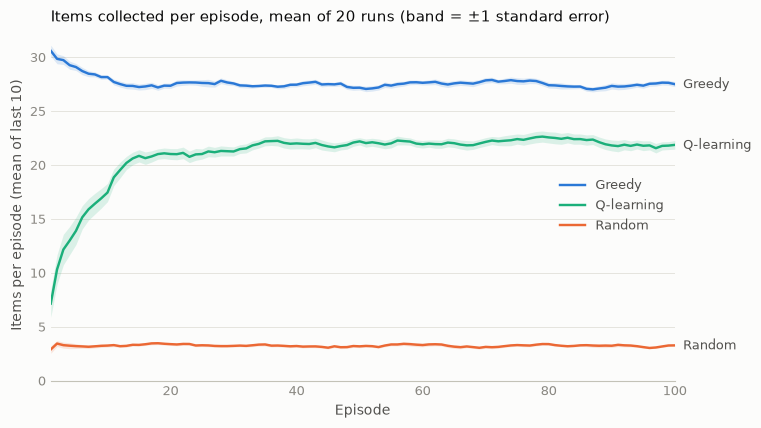

In [4]:
curves = analyse.learning_curves(experiment, ids)
analyse.plot_learning_curves(curves, runs=len(ids))

## Summary

Items per episode in the first and last 10 episodes; `se` is the standard error over runs.

In [5]:
analyse.summary(experiment, ids)

type,runs,first_10,first_se,last_10,last_se
str,u32,f64,f64,f64,f64
"""greedy""",20,28.16,0.19,27.51,0.23
"""q""",20,17.45,0.84,21.87,0.4
"""random""",20,3.26,0.14,3.28,0.09


## What the Q agent learned

The Q agent's state is the direction of the nearest item: `item_rows` is −1 if it's above, 1 if below, 0 if in the same row, and `item_cols` the same for left and right. For each state, this is the move it rates highest at the end of one run, and how many points it expects from it.

In [6]:
q_table = json.loads((data.finished_runs(experiment, ids)[0] / "q_tables.json").read_text())["q1"]["q"]
(pl.DataFrame(q_table, schema=["item_rows", "item_cols", "move", "value"], orient="row")
   .sort("value", descending=True)
   .group_by("item_rows", "item_cols", maintain_order=True).first()     # the best move in each state
   .sort("item_rows", "item_cols"))

item_rows,item_cols,move,value
i64,i64,str,f64
-1,-1,"""up""",13.632263
-1,0,"""up""",14.818287
-1,1,"""up""",13.440821
0,-1,"""left""",15.903325
0,1,"""right""",15.678304
1,-1,"""left""",13.170469
1,0,"""down""",16.370897
1,1,"""down""",11.994712


## Looking further

Every run is recorded in four tables (see `README.md`): `steps` (every move), `events` (every item collected or placed), `metrics` (what the Q agent reported about itself) and `episodes` (totals). `data.scan(table, experiment, ids)` reads one across runs, for example:

```python
data.scan("events", experiment, ids).filter(pl.col("event") == "collect").group_by("agent").len().collect()
```

To try other settings, copy `configs/q_vs_greedy.toml`, give it a new `experiment` name, and load that instead.